# 1. Introduction

**Overview:**

This project covers an analysis of episodes of the TV show The Simpsons, the longest-running American animated TV series and longest running American sitcom. Debuting in 1989, it is currently in its 38th season as of 2026. This project involves acquiring data from two different sources: Wikipedia and IMDb. Wikipedia tables were used for the episode information, such as title, writer, director, etc., and the IMDb database was used to obtain the IMDb rating for each episode. This data was used to analyse the trajectory of the show over the course of its run and how it has changed over that time.

**Tools used:**
- Pandas
- Numpy
- Requests
- Datetime
- Matplotlib
- Seaborn

**Skills used:**
- Web scraping
- Data cleaning
- Exploratory data analysis
- Data visualisation

**Key questions:**
1. How does the viewership of The Simpsons episodes change over time?
2.  How do the IMDb ratings of The Simpsons episodes change over time?
3.  Which writers have the highest IMDb ratings/viewerships?
4.  Which directors have the highest IMDb ratings/viewerships?
5.  Do highly-rated episodes also have high viewing figures and IMDb engagement?

# 2. Data Loading

This section covers loading the data into a Pandas dataframe for use in the analysis. Data for this project was obtained from two distinct sources: Wikipedia (which has webpages that contain tabular information about The Simpsons episodes, such as title, writer, director, etc.) and IMDb (which provides datasets that include user ratings for episodes).

The first step is to import the libraries that will be used during this analysis. These include: Pandas, Numpy, and Matplotlib among others.

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import requests
import datetime as dt
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import re
from io import StringIO

Next, we assign the Wikipedia URLs that will be web-scraped to obtain tabular information about The Simpsons episodes. These tables are split between two webpages - one for seasons 1-20 and another for seasons 21 onwards.

In [2]:
# Assign URLs
URL_1 = 'https://en.wikipedia.org/wiki/List_of_The_Simpsons_episodes_(seasons_1%E2%80%9320)'
URL_2 = 'https://en.wikipedia.org/wiki/List_of_The_Simpsons_episodes_(season_21%E2%80%93present)'

To download the webpages from Wikipedia, we need to add a user-agent header to the request as Wikipedia will deny generic requests.

In [3]:
# Add User-Agent header for request
headers = {
    'User-Agent' : 'SimpsonsDataProject'
}

# Download webpages including User-Aget header
response_1 = requests.get(URL_1, headers = headers)
response_2 = requests.get(URL_2, headers = headers)

In [4]:
# Check if request succeeded
response_1.raise_for_status()
response_2.raise_for_status()

Next, we can extract the tables from the webpages using Pandas.

In [5]:
# Extract HTML tables into a list of DataFrames
episode_tables_1 = pd.read_html(StringIO(response_1.text))
episode_tables_2 = pd.read_html(StringIO(response_2.text))

In [6]:
# Verify loading
episode_tables_1[1].head()

,No. overall,No. in season,Title,Directed by,Written by,Original release date,Prod. code,U.S. viewers (millions)
0,1,1,"""Simpsons Roasting on an Open Fire""",David Silverman,Mimi Pond,"December 17, 1989[51]",7G08,26.7[52]
1,2,2,"""Bart the Genius""",David Silverman,Jon Vitti,"January 14, 1990[53]",7G02,24.5[52]
2,3,3,"""Homer's Odyssey""",Wes Archer,Jay Kogen & Wallace Wolodarsky,"January 21, 1990[54]",7G03,27.5[55]
3,4,4,"""There's No Disgrace Like Home""",Gregg Vanzo & Kent Butterworth,Al Jean & Mike Reiss,"January 28, 1990[56]",7G04,20.2[57]
4,5,5,"""Bart the General""",David Silverman,John Swartzwelder,"February 4, 1990[58]",7G05,27.1[59]


Some of the columns in the tables we have downloaded contain inconsistent column titles due to Wikipedia annotations on some tables. So that all the tables can be assigned to one dataframe, we need to first make sure that all the columns are titled consistently.

In [7]:
# Rename columns so that all tables contain consistent column titles
for i in range(2, 20):
    episode_tables_2[i] = episode_tables_2[i].rename(columns = {
        'Original release date [599]' : 'Original release date',
        'No. in season [a]' : 'No. in season',
        'Title [400]' : 'Title',
        'Original release date [400]' : 'Original release date',
    })

episode_tables_1[21] = episode_tables_1[21].rename(columns = {
    'Original release date [599]' : 'Original release date'
})

Now, we can add the table data to a Pandas dataframe. Note: table number 19 from the first set of tables contains information about The Simpsons Movie which we will not include in this analysis.

In [8]:
# Initialise episodes dataframe
episodes = pd.DataFrame()

In [9]:
# Assign data in tables to episodes dataframe and create a new column to distinguish between seasons
for i,season in enumerate(episode_tables_1[1:19] + episode_tables_1[20:22] + episode_tables_2[2:20], start = 1):
    season['Season'] = i
    episodes = pd.concat([episodes, season], ignore_index = True)

In [10]:
# Verify loading
episodes.head()

,No. overall,No. in season,Title,Directed by,Written by,Original release date,Prod. code,U.S. viewers (millions),Season
0,1.0,1.0,"""Simpsons Roasting on an Open Fire""",David Silverman,Mimi Pond,"December 17, 1989[51]",7G08,26.7[52],1
1,2.0,2.0,"""Bart the Genius""",David Silverman,Jon Vitti,"January 14, 1990[53]",7G02,24.5[52],1
2,3.0,3.0,"""Homer's Odyssey""",Wes Archer,Jay Kogen & Wallace Wolodarsky,"January 21, 1990[54]",7G03,27.5[55],1
3,4.0,4.0,"""There's No Disgrace Like Home""",Gregg Vanzo & Kent Butterworth,Al Jean & Mike Reiss,"January 28, 1990[56]",7G04,20.2[57],1
4,5.0,5.0,"""Bart the General""",David Silverman,John Swartzwelder,"February 4, 1990[58]",7G05,27.1[59],1


In [11]:
# Investigate dataframe size
episodes.shape

(881, 9)

---
Now, in order to obtain information about each episode's IMDb user rating, we need to download the datasets from IMDb. We will be downloading two datasets - the first one has information about episode number and season number, while the second one contains information about user rating and number of votes. Both datasets also contain a unique IMDb episode code that will be used to join the two datasets together. Note: the databases we are downloading are fairly large and contain information about every show on IMDb, though we will only be using the data for The Simpsons.

In [12]:
# Import IMDb databases for episodes and ratings
imdb_episodes = pd.read_csv(
    'https://datasets.imdbws.com/title.episode.tsv.gz',
    sep='\t',
    compression='gzip',
    na_values='\\N'
)

imdb_ratings = pd.read_csv(
    'https://datasets.imdbws.com/title.ratings.tsv.gz',
    sep='\t',
    compression='gzip',
    na_values='\\N'
)

Now, we can extract the data for The Simpsons episodes using the unique code IMDb uses to identify the series.

In [13]:
# Extract The Simpsons episodes from IMDb episodes database
simpsons_episodes = imdb_episodes[
    imdb_episodes['parentTconst'] == 'tt0096697'
].copy()

Next, we can use the unique code IMDb uses to identify individual episodes to merge the two tables into one with information about season number, episode number, user rating, and number of votes.

In [14]:
# Merge the ratings database with The Simpsons episodes table using IMDb episode code
simpsons_ratings = simpsons_episodes.merge(
    imdb_ratings,
    on='tconst',
    how='left'
)

In [15]:
# Verify loading
print(simpsons_ratings.head())

      tconst parentTconst  seasonNumber  episodeNumber  averageRating  \
0  tt0177842    tt0096697           7.0            6.0            8.7   
1  tt0348034    tt0096697           1.0            1.0            8.1   
2  tt0701040    tt0096697           5.0           10.0            8.6   
3  tt0701041    tt0096697           6.0           22.0            8.1   
4  tt0701042    tt0096697          14.0           16.0            7.1   

   numVotes  
0    4581.0  
1   10763.0  
2    4401.0  
3    3794.0  
4    1833.0  


# 3. Data Cleaning

We now have two datasets - one from Wikipedia and one from IMDb. We will first clean up the episodes dataframe a bit and then join the two datasets together.

In [16]:
# Investigate data types of columns
episodes.dtypes

No. overall                object
No. in season              object
Title                         str
Directed by                   str
Written by                    str
Original release date         str
Prod. code                    str
U.S. viewers (millions)       str
Season                      int64
dtype: object

We can see that the episodes dataframe contains several columns with data types that are not appropriate. For example: No. overall and No. in season have the data type 'object', and U.S. viewers (millions) and Original release date have the data type 'string'.

No. overall and No. in season would be more useful as integer values. Before we convert these columns to integers, we should remove any annotations that might be contained in the data. Wikipedia tables often have footnote annotations contained in square brackets embedded into the data. No. in season also contains entries that do not have episode numbers (for example: Disney+ specials) so the episode number is represented by '–' instead. For our analysis, we will change these values to NaN.

In [17]:
# Remove annotations in No. overall column and convert to integer values
episodes['No. overall'] = pd.to_numeric(
    episodes['No. overall']
    .astype('string')
    .str.replace(r'\[.*?\]', '', regex = True)
).astype('Int64')

episodes['No. overall'].dtype

Int64Dtype()

In [18]:
# Replace '–' values with NaN and convert No.in season column to integer values
episodes['No. in season'] = pd.to_numeric(
    episodes['No. in season']
    .replace('–', np.nan, regex = True)
    ).astype('Int64')

episodes['No. in season'].dtype

Int64Dtype()

For some earlier episodes, U.S. viewers (millions) contains data about both number of individual viewers and number of households (HH). Wikipedia annotations are also included in this column. We can extract the first numerical value from this column to ignore both HH values and annotations. We can then convert the column to an appropriate data type (float).

In [19]:
# Extract the first numerical value from the viewers column to account for HH values in earlier seasons
episodes['U.S. viewers (millions)'] =  (
    episodes['U.S. viewers (millions)']
    .str.extract(r'^(\d+\.?\d*)')[0]
)

In [20]:
# Convert viewers column into float datatype
episodes['U.S. viewers (millions)'] = pd.to_numeric(episodes['U.S. viewers (millions)'])
episodes['U.S. viewers (millions)'].dtype

dtype('float64')

An appropriate data type for the Original release date column is datetime, so we can remove annotations and convert this column's data type.

In [21]:
# Remove the [] annotations and convert release date column to datetime datatype
episodes['Original release date'] = pd.to_datetime(
    episodes['Original release date']
    .str.replace(r'\[.*?\]', '', regex=True)
)

Now, we can check for any further annotations in the remaining columns, all of which have the data type 'string'.

In [22]:
# Check for any further annotations
for col in episodes.select_dtypes(include='str'):
    count = episodes[col].str.contains(r'\[.*?\]', na = False).sum()

    if count > 0:
        print(f'{col}: {count} annotations')

Title: 7 annotations
Directed by: 2 annotations
Written by: 3 annotations
Prod. code: 3 annotations


Before we remove these annotations, we should investigate them to make sure they do not contain any important information. Once we have verified that this is the case, we can safely remove all the annotations.

In [23]:
cols = ['Title', 'Directed by', 'Written by', 'Prod. code']

for col in cols:
    mask = episodes[col].str.contains(r'\[.*?\]', na = False)

    print(f'\n--- {col} ---')
    print(episodes.loc[mask, col])


--- Title ---
874                           "Jersey Score"[420]
875                 "Don't Marge with Texas"[421]
876                                    "Bog"[422]
877                        "The Offendables"[423]
878    "Lock, Stock and One Stupid Narrator"[424]
879               "Billionaire on the Bayou"[425]
880                     "Lenny Goes Squiggy"[426]
Name: Title, dtype: str

--- Directed by ---
7      Rich Moore Kent Butterworth (uncredited)[64]
156                              David Silverman[a]
Name: Directed by, dtype: str

--- Written by ---
118     Jon Vitti[a]
156     Jon Vitti[b]
398    Dana Gould[b]
Name: Written by, dtype: str

--- Prod. code ---
184    3F25[314] 3G01
187    3F27[319] 3G03
205    3F26[336] 3G02
Name: Prod. code, dtype: str


In [24]:
# Remove annotations
for col in cols:
    episodes[col] = (
        episodes[col]
        .str.replace(r'\[.*?\]', '', regex = True)
        .str.strip()
    )

In [25]:
# Check dataframe
episodes.head()

,No. overall,No. in season,Title,Directed by,Written by,Original release date,Prod. code,U.S. viewers (millions),Season
0,1,1,"""Simpsons Roasting on an Open Fire""",David Silverman,Mimi Pond,1989-12-17,7G08,26.7,1
1,2,2,"""Bart the Genius""",David Silverman,Jon Vitti,1990-01-14,7G02,24.5,1
2,3,3,"""Homer's Odyssey""",Wes Archer,Jay Kogen & Wallace Wolodarsky,1990-01-21,7G03,27.5,1
3,4,4,"""There's No Disgrace Like Home""",Gregg Vanzo & Kent Butterworth,Al Jean & Mike Reiss,1990-01-28,7G04,20.2,1
4,5,5,"""Bart the General""",David Silverman,John Swartzwelder,1990-02-04,7G05,27.1,1


---
Now that the episodes dataframe has been cleaned up a bit, we can add the data from the IMDb ratings dataset. Let's first investigate the data types in the ratings dataset to ensure they are appropriate.

In [26]:
simpsons_ratings.dtypes

tconst               str
parentTconst         str
seasonNumber     float64
episodeNumber    float64
averageRating    float64
numVotes         float64
dtype: object

We can convert the seasonNumber, episodeNumber, and numVotes columns to integer data types.

In [27]:
# Convert seasonNumber and episodeNumber to integer values
simpsons_ratings['seasonNumber'] = simpsons_ratings['seasonNumber'].astype('Int64')
simpsons_ratings['episodeNumber'] = simpsons_ratings['episodeNumber'].astype('Int64')
simpsons_ratings['numVotes'] = simpsons_ratings['numVotes'].astype('Int64')

Now, we are ready to merge the episodes and the simpsons_ratings data. We can use season and episode numbers to merge the data.

In [28]:
# Merge the simpsons_ratings table with the episodes dataframe using season and episode numbers
episodes = episodes.merge(
    simpsons_ratings[
        ['seasonNumber', 'episodeNumber', 'averageRating', 'numVotes']
        ],
    left_on = ['Season', 'No. in season'],
    right_on = ['seasonNumber', 'episodeNumber'],
    how = 'left'
)

Some episodes, such as unreleased episodes and Disney+ specials without episode numbers, will not have been assigned an IMDb user rating. We can investigate how many of these episodes there are in the data.

In [29]:
# Find episodes that don't have IMDb ratings
print(
    "Episodes without IMDb ratings:",
    episodes['averageRating'].isna().sum()
)

Episodes without IMDb ratings: 39


In [30]:
# Check dataframe
episodes.head()

,No. overall,No. in season,Title,Directed by,Written by,Original release date,Prod. code,U.S. viewers (millions),Season,seasonNumber,episodeNumber,averageRating,numVotes
0,1,1,"""Simpsons Roasting on an Open Fire""",David Silverman,Mimi Pond,1989-12-17,7G08,26.7,1,1,1,8.1,10763
1,2,2,"""Bart the Genius""",David Silverman,Jon Vitti,1990-01-14,7G02,24.5,1,1,2,7.6,7524
2,3,3,"""Homer's Odyssey""",Wes Archer,Jay Kogen & Wallace Wolodarsky,1990-01-21,7G03,27.5,1,1,3,7.3,6716
3,4,4,"""There's No Disgrace Like Home""",Gregg Vanzo & Kent Butterworth,Al Jean & Mike Reiss,1990-01-28,7G04,20.2,1,1,4,7.6,6496
4,5,5,"""Bart the General""",David Silverman,John Swartzwelder,1990-02-04,7G05,27.1,1,1,5,7.9,6694


Note that our dataframe now contains several redundant columns - two for season number and two for episode number. After verifying that these columns contain matching values, we can remove these redundant columns.

In [31]:
# Check whether Season and seasonNumber column match
(episodes['Season'] == episodes['seasonNumber']).all()

np.True_

In [32]:
# Check whether No. in season and episodeNumber match
(episodes['No. in season'] == episodes['episodeNumber']).all()

np.True_

In [33]:
# Remove redundant columns
episodes = episodes.drop(columns = ['seasonNumber', 'episodeNumber'])

Our dataframe also has columns named using different naming practices, so it would be helpful to standardise the column names.

In [34]:
# Standardise column names
episodes = episodes.rename(columns = {
    'Season' : 'season_number',
    'No. overall' : 'episode_number_overall',
    'No. in season' : 'episode_number',
    'Title' : 'title',
    'Directed by' : 'director',
    'Written by' : 'writer',
    'Original release date' : 'release_date',
    'Prod. code' : 'production_code',
    'U.S. viewers (millions)' : 'us_viewers_millions',
    'averageRating' : 'average_rating',
    'numVotes' : 'num_votes'
})

# Re-order dataframe
episodes = episodes[['episode_number_overall', 'episode_number', 'season_number',
                     'title', 'director', 'writer',
                     'release_date', 'production_code', 'us_viewers_millions',
                     'average_rating', 'num_votes']]

In [35]:
# Check dataframe
episodes.head()

,episode_number_overall,episode_number,season_number,title,director,writer,release_date,production_code,us_viewers_millions,average_rating,num_votes
0,1,1,1,"""Simpsons Roasting on an Open Fire""",David Silverman,Mimi Pond,1989-12-17,7G08,26.7,8.1,10763
1,2,2,1,"""Bart the Genius""",David Silverman,Jon Vitti,1990-01-14,7G02,24.5,7.6,7524
2,3,3,1,"""Homer's Odyssey""",Wes Archer,Jay Kogen & Wallace Wolodarsky,1990-01-21,7G03,27.5,7.3,6716
3,4,4,1,"""There's No Disgrace Like Home""",Gregg Vanzo & Kent Butterworth,Al Jean & Mike Reiss,1990-01-28,7G04,20.2,7.6,6496
4,5,5,1,"""Bart the General""",David Silverman,John Swartzwelder,1990-02-04,7G05,27.1,7.9,6694


Now, let's check the dataframe for any missing values.

In [36]:
# Check for missing values
episodes.isna().sum()

episode_number_overall    22
episode_number            30
season_number              0
title                     22
director                  22
writer                    22
release_date              22
production_code           22
us_viewers_millions       40
average_rating            39
num_votes                 39
dtype: int64

Some missing values can probably be explained by unreleased episodes, but it is worth investigating these missing values.

In [37]:
# Check for missing episodes
missing_check = episodes[
    episodes.isna().any(axis = 1)
    ]

missing_check.head()

,episode_number_overall,episode_number,season_number,title,director,writer,release_date,production_code,us_viewers_millions,average_rating,num_votes
18,<NA>,<NA>,2,NaN,NaN,NaN,NaT,NaN,NaN,NaN,<NA>
47,<NA>,<NA>,3,NaN,NaN,NaN,NaT,NaN,NaN,NaN,<NA>
72,<NA>,<NA>,4,NaN,NaN,NaN,NaT,NaN,NaN,NaN,<NA>
98,<NA>,<NA>,5,NaN,NaN,NaN,NaT,NaN,NaN,NaN,<NA>
124,<NA>,<NA>,6,NaN,NaN,NaN,NaT,NaN,NaN,NaN,<NA>


There are some rows where all values except season_number are missing. This is potentially due to formatting errors when importing tables from Wikipedia, so these rows can be removed.

In [38]:
# Remove entries with missing titles
episodes = episodes.dropna(subset = ['title'])

We should also investigate rows with missing episode numbers (these are potentially the result of Disney+ specials) and rows with missing viewing figures (these are potentially made up of Disney+ specials and unreleased episodes).

In [39]:
# Investigate missing episode numbers
episodes[episodes['episode_number'].isna()].head()

,episode_number_overall,episode_number,season_number,title,director,writer,release_date,production_code,us_viewers_millions,average_rating,num_votes
832,778,<NA>,36,"""O C'mon All Ye Faithful""",Debbie Bruce Mahan,Carolyn Omine,2024-12-17,35ABF21,NaN,NaN,<NA>
833,779,<NA>,36,"""O C'mon All Ye Faithful""",Matthew Faughnan,Carolyn Omine,2024-12-17,35ABF22,NaN,NaN,<NA>
837,782,<NA>,36,"""The Past and the Furious""",Mike Frank Polcino,Rob LaZebnik,2025-02-12,35ABF19,NaN,NaN,<NA>
841,786,<NA>,36,"""Yellow Planet""",Timothy Bailey,J. Stewart Burns,2025-04-22,35ABF20,NaN,NaN,<NA>
861,806,<NA>,37,"""Extreme Makeover: Homer Edition""",Matthew Nastuk,Michael Price,2026-06-17,36ABF20,NaN,NaN,<NA>


In [40]:
# Investigate missing viewing figures
episodes[episodes['us_viewers_millions'].isna()].tail()

,episode_number_overall,episode_number,season_number,title,director,writer,release_date,production_code,us_viewers_millions,average_rating,num_votes
876,820,11,38,"""Bog""",TBA,TBA,2026-12-13,TBA,NaN,NaN,<NA>
877,821,12,38,"""The Offendables""",TBA,TBA,2026-12-20,TBA,NaN,NaN,<NA>
878,822,13,38,"""Lock, Stock and One Stupid Narrator""",TBA,TBA,2026-12-27,TBA,NaN,NaN,<NA>
879,823,14,38,"""Billionaire on the Bayou""",TBA,TBA,2027-01-03,TBA,NaN,NaN,<NA>
880,824,15,38,"""Lenny Goes Squiggy""",TBA,TBA,2027-01-03,TBA,NaN,NaN,<NA>


For the sake of consistency, we can replace TBA values in upcoming episodes with NaN.

In [41]:
# Replace TBA values in upcoming episodes
episodes = episodes.replace('TBA', np.nan)

In the writer and director columns, they often contain multiple credits. For the analysis, it may be useful to split up these credits into lists of individual writers and directors. We can do this using a function.

In [42]:
# Define function to split up writing/directing credits
def split_credits(value):
    if pd.isna(value):
        return []

    # Remove writing-role labels
    value = re.sub(
        r'\*?(?:Story|Teleplay|Written)\s+by\*?\s*[:：]\s*',
        '',
        value,
        flags = re.IGNORECASE
    )

    # Remove remaining markdown formatting
    value = value.replace('*', '')

    # Split individual names
    names = re.split(r'\s*(?:,|&|\band\b|\n|\\)\s*', value)

    return [name.strip() for name in names if name.strip()]

In [43]:
# Split multiple writers into lists
episodes['writer'] = episodes['writer'].apply(split_credits)

In [44]:
# Split multiple directors into lists
episodes['director'] = episodes['director'].apply(split_credits)

In [45]:
# Check dataframe
episodes.head()

,episode_number_overall,episode_number,season_number,title,director,writer,release_date,production_code,us_viewers_millions,average_rating,num_votes
0,1,1,1,"""Simpsons Roasting on an Open Fire""",[David Silverman],[Mimi Pond],1989-12-17,7G08,26.7,8.1,10763
1,2,2,1,"""Bart the Genius""",[David Silverman],[Jon Vitti],1990-01-14,7G02,24.5,7.6,7524
2,3,3,1,"""Homer's Odyssey""",[Wes Archer],"[Jay Kogen, Wallace Wolodarsky]",1990-01-21,7G03,27.5,7.3,6716
3,4,4,1,"""There's No Disgrace Like Home""","[Gregg Vanzo, Kent Butterworth]","[Al Jean, Mike Reiss]",1990-01-28,7G04,20.2,7.6,6496
4,5,5,1,"""Bart the General""",[David Silverman],[John Swartzwelder],1990-02-04,7G05,27.1,7.9,6694


There are several entries in the dataframe that contain repeated episode numbers. These are due to anthology episodes such as Treehouse of Horror specials. It is important to be aware of this during analysis.

In [46]:
# Investigate repeated episode numbers
episodes[
    episodes.duplicated(
        subset = ['episode_number_overall'],
        keep = False
    )
    ].sort_values(['episode_number_overall']).head()

,episode_number_overall,episode_number,season_number,title,director,writer,release_date,production_code,us_viewers_millions,average_rating,num_votes
15,16,3,2,"""Treehouse of Horror""",[Wes Archer],[John Swartzwelder],1990-10-25,7F04,27.4,8.2,6621
16,16,3,2,"""Treehouse of Horror""",[Rich Moore],"[Jay Kogen, Wallace Wolodarsky]",1990-10-25,7F04,27.4,8.2,6621
17,16,3,2,"""Treehouse of Horror""",[David Silverman],"[Edgar Allan Poe, Sam Simon]",1990-10-25,7F04,27.4,8.2,6621
44,42,7,3,"""Treehouse of Horror II""",[Jim Reardon],"[Al Jean, Mike Reiss]",1991-10-31,8F02,20.0,8.2,5127
45,42,7,3,"""Treehouse of Horror II""",[Jim Reardon],"[Jeff Martin, George Meyer]",1991-10-31,8F02,20.0,8.2,5127


# 4. Exploratory Data Analysis & Visualisations

## 4.0 Notable Episodes

For the sake of curiosity, here are a few notable episodes of The Simpsons:

In [47]:
# Episode with highest number of U.S. viewers
highest_viewers = episodes[episodes['us_viewers_millions'] == episodes['us_viewers_millions'].max()]
print("The episode with the highest number of U.S. viewers is season", highest_viewers['season_number'].iloc[0], "episode", highest_viewers['episode_number'].iloc[0],
     "-", highest_viewers['title'].iloc[0],)

The episode with the highest number of U.S. viewers is season 2 episode 1 - "Bart Gets an 'F'"


In [48]:
# Episode with highest IMDb rating
highest_rating = episodes[episodes['average_rating'] == episodes['average_rating'].max()]
print("The episode with the highest IMDb rating is season", highest_rating['season_number'].iloc[0], "episode", highest_rating['episode_number'].iloc[0],
     "-", highest_rating['title'].iloc[0],)

The episode with the highest IMDb rating is season 8 episode 23 - "Homer's Enemy"


In [49]:
# Episode with lowest number of U.S. viewers
lowest_viewers = episodes[episodes['us_viewers_millions'] == episodes['us_viewers_millions'].min()]
print("The episode with the lowest number of U.S. viewers is season", lowest_viewers['season_number'].iloc[0], "episode", lowest_viewers['episode_number'].iloc[0],
     "-", lowest_viewers['title'].iloc[0],)

The episode with the lowest number of U.S. viewers is season 36 episode 18 - "Estranger Things"


In [50]:
# Episode with lowest IMDb rating
lowest_rating = episodes[episodes['average_rating'] == episodes['average_rating'].min()]
print("The episode with the lowest IMDb rating is season", lowest_rating['season_number'].iloc[0], "episode", lowest_rating['episode_number'].iloc[0],
     "-", lowest_rating['title'].iloc[0],)

The episode with the lowest IMDb rating is season 23 episode 22 - "Lisa Goes Gaga"


## 4.1 Viewership Trends

Let's investigate the U.S. viewing figures of The Simpsons over the course of its run.

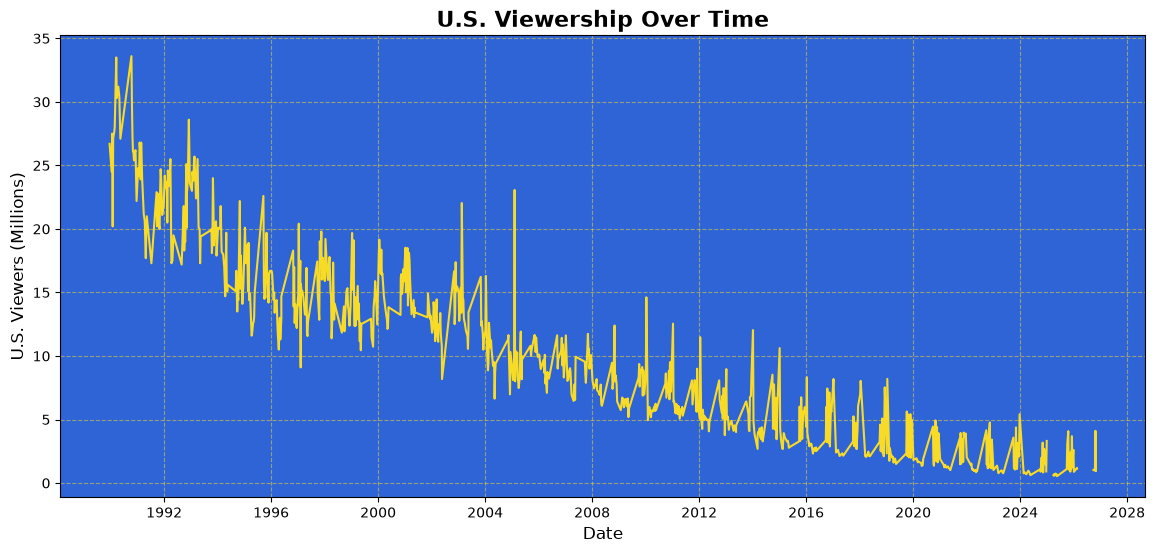

In [51]:
# Plot a graph of U.S. viewership over time
plt.figure (figsize = (14, 6))

plt.plot(
    episodes['release_date'],
    episodes['us_viewers_millions'],
    color = '#f8db27'
)

plt.title('U.S. Viewership Over Time', fontsize = 16, fontweight = 'bold')
plt.xlabel('Date', fontsize = 12)
plt.ylabel('U.S. Viewers (Millions)', fontsize = 12)
plt.grid(linestyle = '--', alpha = 0.5, color = '#f8db27')

ax = plt.gca()
ax.set_facecolor('#2f64d6')

plt.show()

The viewership of The Simpsons appears to have steadily decreased over time. There are notable exceptions to this and peaks within seasons for particular episodes. We can see the trend more clearly if we plot the average number of viewers by season rather than by episode.

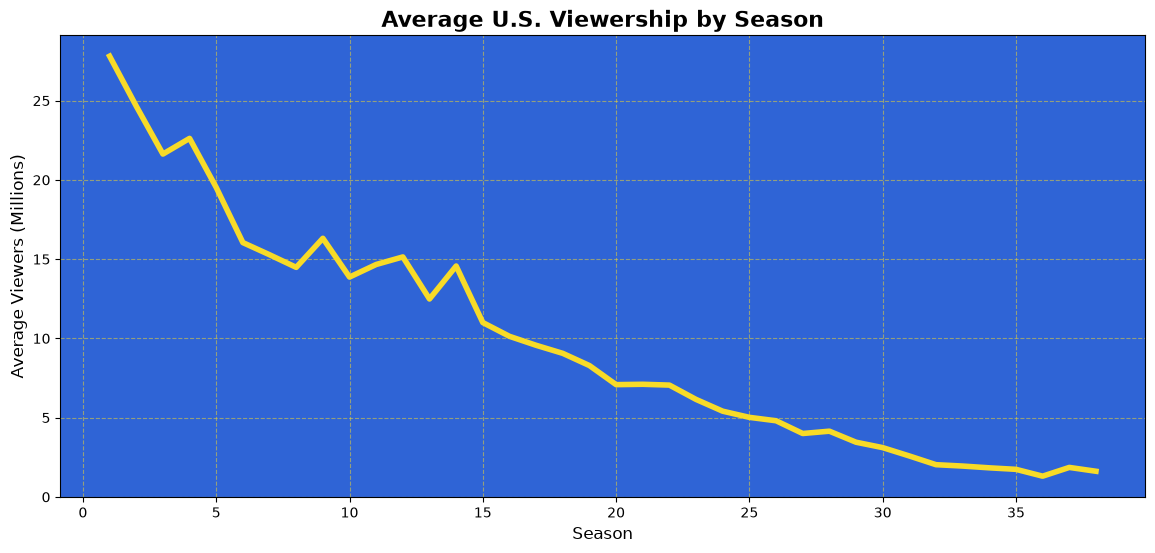

In [52]:
# Find mean viewership for each season
season_viewership = (
    episodes.groupby('season_number')['us_viewers_millions'].mean()
)

# Plot mean viewership by season
plt.figure(figsize = (14, 6))

plt.plot(season_viewership, color = '#f8db27', linewidth = 4)

plt.title("Average U.S. Viewership by Season", fontsize = 16, fontweight = 'bold')
plt.xlabel("Season", fontsize = 12)
plt.ylabel("Average Viewers (Millions)", fontsize = 12)
plt.grid(linestyle = '--', alpha = 0.5, color = '#f8db27')

ax = plt.gca()
ax.set_facecolor('#2f64d6')

plt.show()

## 4.2 IMDb Rating Trends

Let's investigate the trends in the IMDb user ratings of The Simpsons over the course of its run.

In [53]:
# Find the maximum and minimum values of IMDb user rating
print("Maximum IMDb user rating:", episodes['average_rating'].max())
print("Minimum IMDb user rating:", episodes['average_rating'].min())

Maximum IMDb user rating: 9.3
Minimum IMDb user rating: 4.0


We can see that the IMDb user rating covers a wide range (user rating can be a value from 1 to 10). We can investigate how this trend develops over time with a line graph.

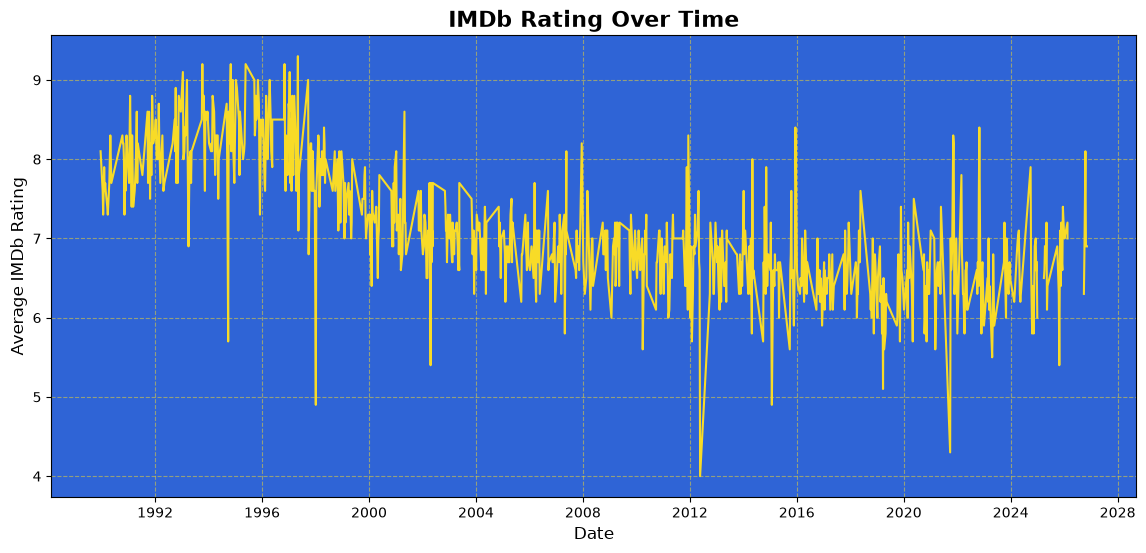

In [54]:
# Plot a graph of IMDb rating over time
plt.figure (figsize = (14, 6))

plt.plot(
    episodes['release_date'],
    episodes['average_rating'],
    color = '#f8db27'
)

plt.title('IMDb Rating Over Time', fontsize = 16, fontweight = 'bold')
plt.xlabel('Date', fontsize = 12)
plt.ylabel('Average IMDb Rating', fontsize = 12)
plt.grid(linestyle = '--', alpha = 0.5, color = '#f8db27')

ax = plt.gca()
ax.set_facecolor('#2f64d6')

plt.show()

Individual episodes can have particularly high or particularly low user ratings (for example: "Lisa Goes Gaga" sits at an IMDb rating of 4.0), so we can see the overall trend more clearly if we plot the average rating by season.

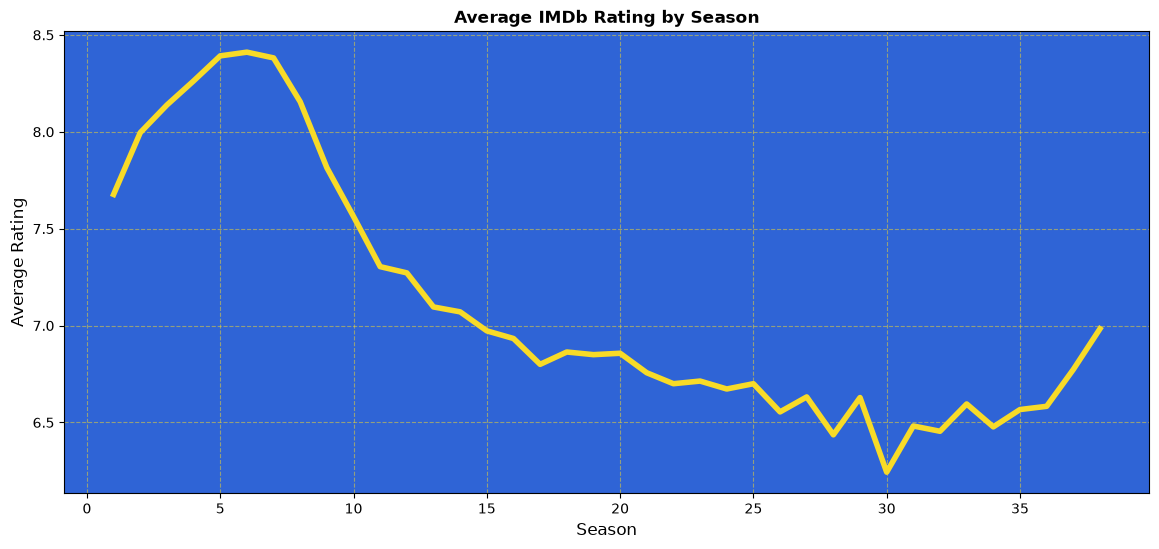

In [55]:
# Find mean IMDb rating for each season
season_rating = (
    episodes.groupby('season_number')['average_rating'].mean()
)

# Plot mean IMDb rating by season
plt.figure(figsize = (14, 6))

plt.plot(season_rating, color = '#f8db27', linewidth = 4)

plt.title("Average IMDb Rating by Season", fontsize = 12, fontweight = 'bold')
plt.xlabel("Season", fontsize = 12)
plt.ylabel("Average Rating", fontsize = 12)
plt.grid(linestyle = '--', alpha = 0.5, color = '#f8db27')

ax = plt.gca()
ax.set_facecolor('#2f64d6')

plt.show()

Overall, The Simpsons has seen a decrease in IMDb user rating over time, however there are a few notable exceptions. In the show's early seasons, each season's average IMDb rating increased before reaching its peak at season 6. It then began to decrease steadily (with a few wobbles) until reaching its lowest point at season 30. After this, it began to increase again slightly. It is also notable that the show's average IMDb user rating stays above 8.0 only for seasons 3-8, widely considered to be the "Golden Age" of The Simpsons.

We can also see the trends in the show's IMDb rating using a heatmap, which allows us to clearly identify particularly low-rated or high-rated episodes in the show's run.

In [56]:
# Create heatmap data
rating_heatmap_data = episodes.pivot_table(
    index = 'episode_number',
    columns = 'season_number',
    values = 'average_rating',
    aggfunc = 'mean'
)

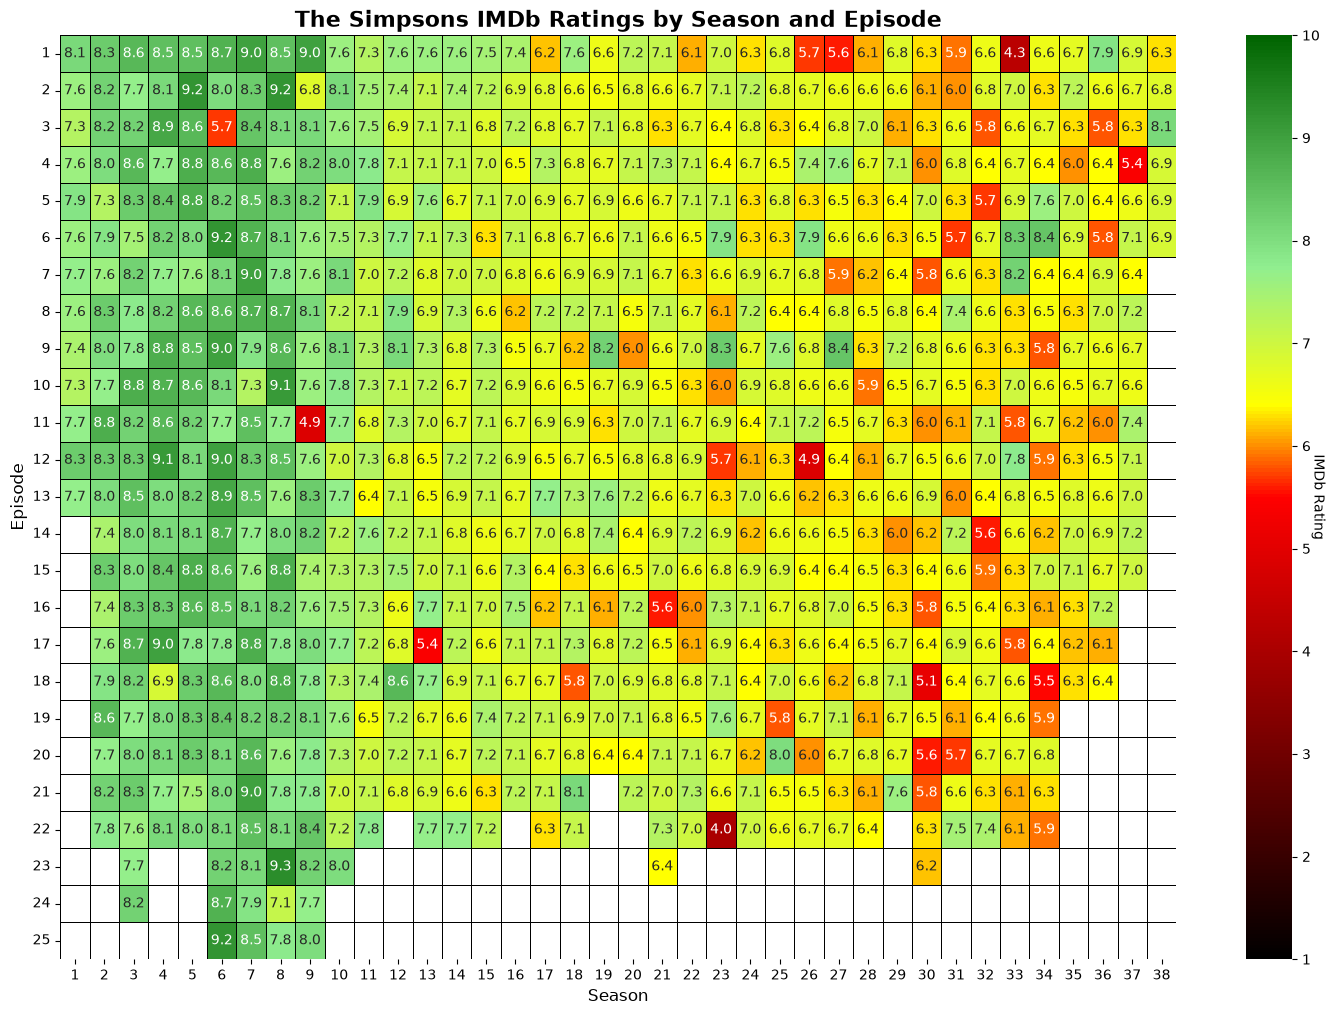

In [57]:
# Create colourmap
colours = [
    (0, 'black'),
    (0.5, 'red'),
    (0.6, 'yellow'),
    (0.75, 'lightgreen'),
    (1, 'darkgreen')
]

custom_cmap = LinearSegmentedColormap.from_list(
    'average_rating',
    colours
)

# Plot heatmap
plt.figure(figsize = (18, 12))

ax = sns.heatmap(
    rating_heatmap_data,
    cmap = custom_cmap,
    vmin = 1,
    vmax = 10,
    linewidths = 0.5,
    linecolor = 'black',
    annot = True,
    annot_kws = {'size' : 10},
    fmt = '.1f'
)

ax.collections[0].colorbar.set_label(
    'IMDb Rating',
    rotation=270
)

plt.xlabel('Season', fontsize = 12)
plt.ylabel('Episode', fontsize = 12)
plt.yticks(rotation = 0)
plt.title('The Simpsons IMDb Ratings by Season and Episode', fontsize = 16, fontweight = 'bold')

plt.show()

Notable early-season low-scoring episodes include "Another Simpsons Clip Show" (season 6 episode 3) and "All Singing, All Dancing" (season 9 episode 11).

## 4.3 Top Writers

Let's investigate the top writers for The Simpsons. We first need to split up the lists of writers that we created earlier for episodes with multiple writers.

In [58]:
# Create individual entries for each writer for episodes with multiple writers
writers = episodes.copy()
writers = writers.explode('writer')
writers['writer'] = writers['writer'].str.strip()

Now, we need to calculate the number of episodes each writer wrote and the average IMDb user ratings for their episodes.

In [59]:
# Calculate number of episodes written and average rating for each writer
writer_stats = (
    writers.groupby('writer')
    .agg(
        episodes_written = ('episode_number_overall', 'nunique'),
        average_rating = ('average_rating', 'mean'),
    )
    .sort_values('episodes_written', ascending=False)
)

writer_stats.head()

,episodes_written,average_rating
writer,,
John Swartzwelder,58,7.893103
John Frink,39,6.766667
Joel H. Cohen,38,6.707895
Tim Long,36,6.569444
Carolyn Omine,30,6.940741


We can plot this on a bar chart to see the most prolific Simpsons writers in a more visual way.

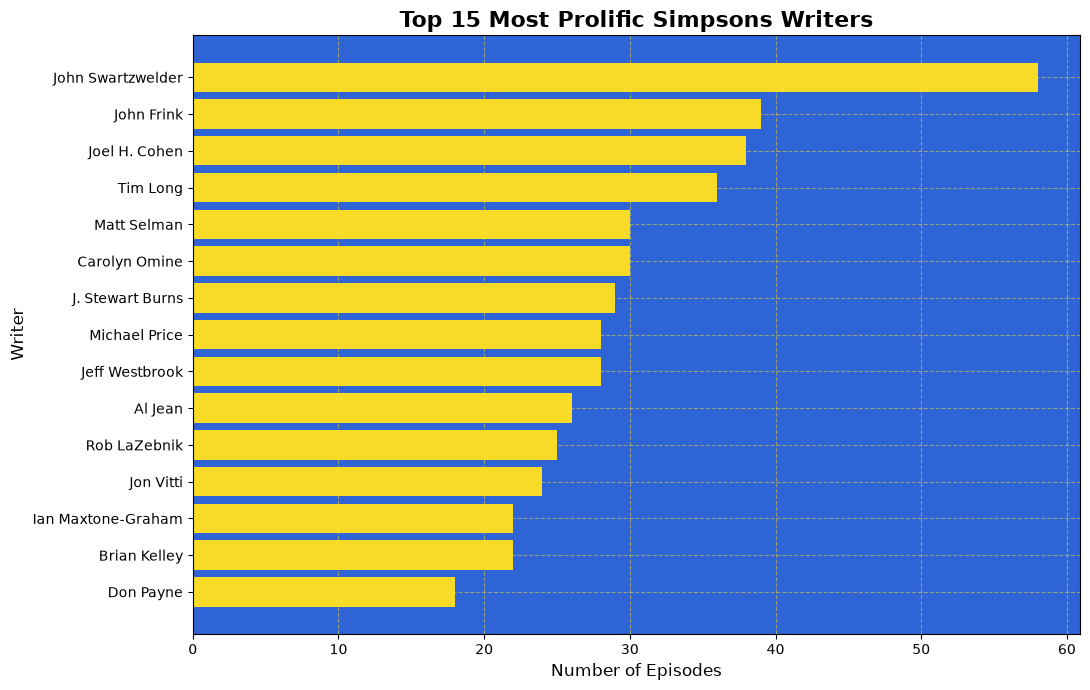

In [60]:
# Find top 15 most prolific writers
top_writers = writer_stats.head(15).sort_values('episodes_written')

# Plot top 15 most prolific writers
plt.figure(figsize = (11, 7))

plt.barh(
    top_writers.index,
    top_writers['episodes_written'],
    color = '#f8db27'
)

plt.title('Top 15 Most Prolific Simpsons Writers', fontsize = 16, fontweight = 'bold')
plt.xlabel('Number of Episodes', fontsize = 12)
plt.ylabel('Writer', fontsize = 12)
plt.grid(linestyle = '--', alpha = 0.5, color = '#f8db27')

ax = plt.gca()
ax.set_facecolor('#2f64d6')

plt.tight_layout()
plt.show()

The most prolific writer for The Simpsons is John Swartzwelder by some margin.

Now, let's calculate the writers with the highest average IMDb user ratings for their episodes (minimum 5 episodes).

In [61]:
# Calculate the writers with the highest average IMDb rating
top_rated_writers = (
    writer_stats[writer_stats['episodes_written'] >=5]
    .sort_values('average_rating', ascending = False)
    .head(15)
)

top_rated_writers.head()

,episodes_written,average_rating
writer,,
Greg Daniels,8,8.675000
Josh Weinstein,13,8.361538
Bill Oakley,13,8.361538
Jonathan Collier,6,8.333333
Jennifer Crittenden,5,8.260000


We can view this more visually with a bar chart.

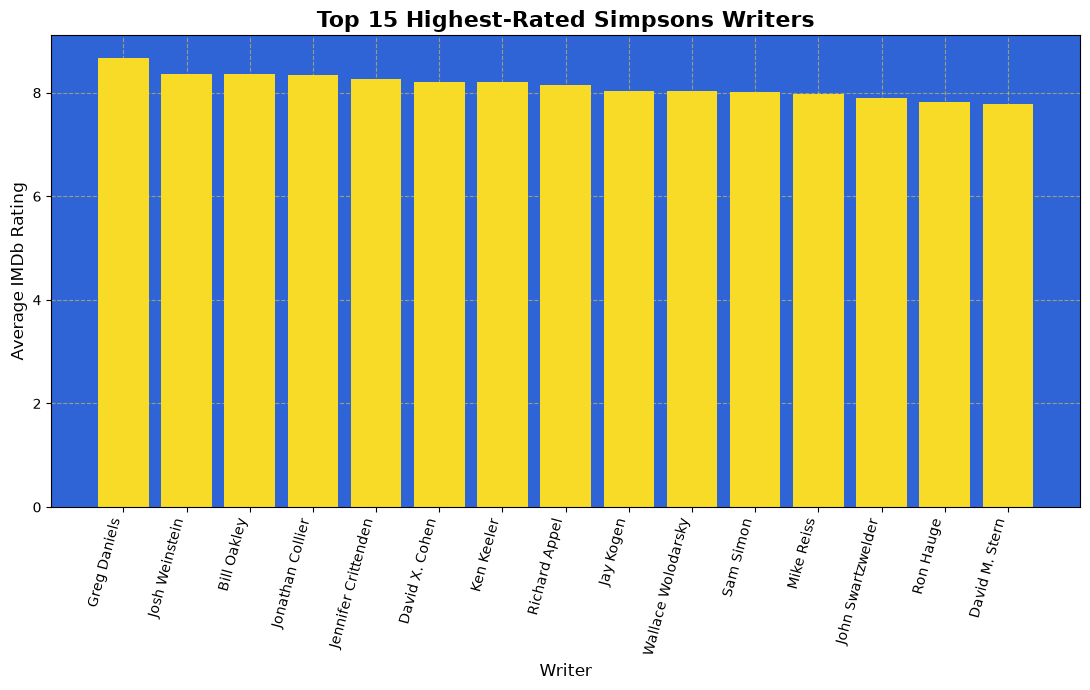

In [62]:
# Plot top 15 highest-rated Simpsons writers
plt.figure(figsize = (11, 7))

plt.bar(
    top_rated_writers.index,
    top_rated_writers['average_rating'],
    color = '#f8db27'
)

plt.title('Top 15 Highest-Rated Simpsons Writers', fontsize = 16, fontweight = 'bold')
plt.xlabel('Writer', fontsize = 12)
plt.ylabel('Average IMDb Rating', fontsize = 12)
plt.xticks(rotation = 75, ha ='right')
plt.grid(linestyle = '--', alpha = 0.5, color = '#f8db27')

ax = plt.gca()
ax.set_facecolor('#2f64d6')

plt.tight_layout()
plt.show()

Greg Daniels is the writer with the highest average rating for his episodes.

## 4.4 Top Directors

Now, let's investigate the top directors for The Simpsons. As with writers, we first need to split up the lists of directors that we created earlier for episodes with multiple directors.

In [63]:
# Create individual entries for each director for episodes with multiple directors
directors = episodes.copy()
directors = directors.explode('director')
directors['director'] = directors['director'].str.strip()

Now, we need to calculate the number of episodes directed and the average IMDb user ratings for their episodes for each director.

In [64]:
# Calculate number of episodes directed and average rating for each director
director_stats = (
    directors.groupby('director')
    .agg(
        episodes_directed = ('episode_number_overall', 'nunique'),
        average_rating = ('average_rating', 'mean'),
    )
    .sort_values('episodes_directed', ascending=False)
)

director_stats.head()

,episodes_directed,average_rating
director,,
Steven Dean Moore,87,6.921348
Mark Kirkland,84,7.310465
Matthew Nastuk,68,6.688406
Bob Anderson,66,6.977143
Mike Frank Polcino,45,6.563636


We can plot this on a bar chart to see the most prolific Simpsons directors in a more visual way.

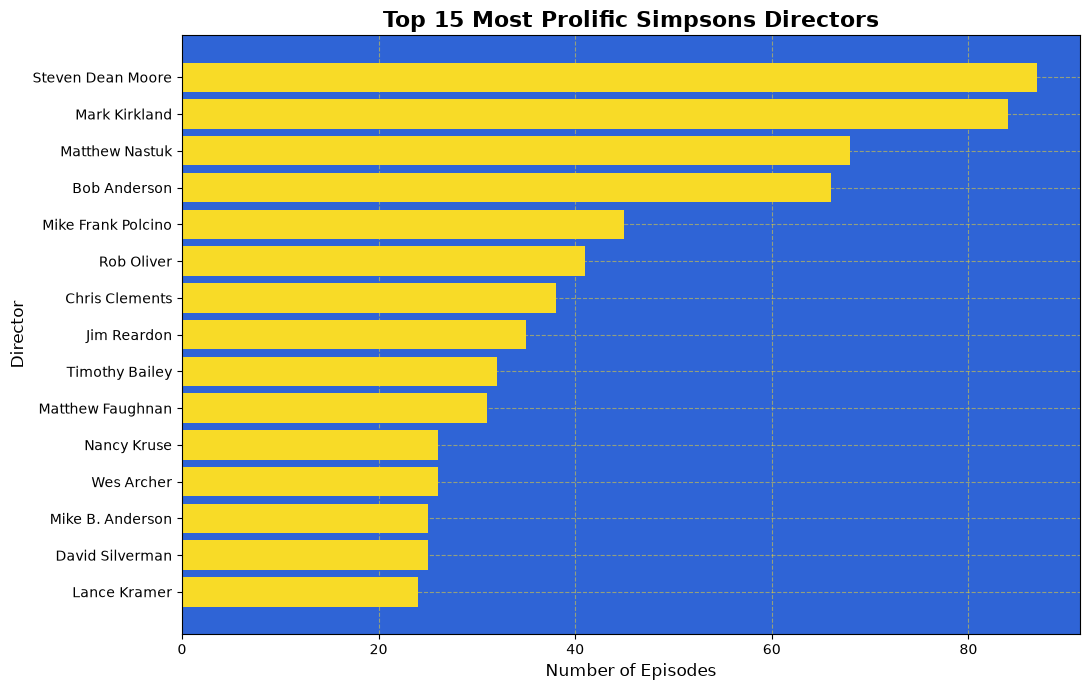

In [65]:
#Calculate top 15 most prolific directors
top_directors = director_stats.head(15).sort_values('episodes_directed')

# plot top 15 most prolific directors
plt.figure(figsize = (11, 7))

plt.barh(
    top_directors.index,
    top_directors['episodes_directed'],
    color = '#f8db27'
)

plt.title('Top 15 Most Prolific Simpsons Directors', fontsize = 16, fontweight = 'bold')
plt.xlabel('Number of Episodes', fontsize = 12)
plt.ylabel('Director', fontsize = 12)
plt.grid(linestyle = '--', alpha = 0.5, color = '#f8db27')

ax = plt.gca()
ax.set_facecolor('#2f64d6')

plt.tight_layout()
plt.show()

The most prolific Simpsons director is Steven Dean Moore, closely followed by Mark Kirkland.

Now, let's calculate the directors with the highest average IMDb user ratings (minimum 5 episodes).

In [66]:
# Calculate the directors with the highest average IMDb rating
top_rated_directors = (
    director_stats[director_stats['episodes_directed'] >=5]
    .sort_values('average_rating', ascending = False)
    .head(15)
)

top_rated_directors.head()

,episodes_directed,average_rating
director,,
Rich Moore,16,8.312500
Jeffrey Lynch,12,8.300000
Jim Reardon,35,8.241463
Wes Archer,26,8.188462
Carlos Baeza,9,8.181818


We can view this more visually using a bar chart.

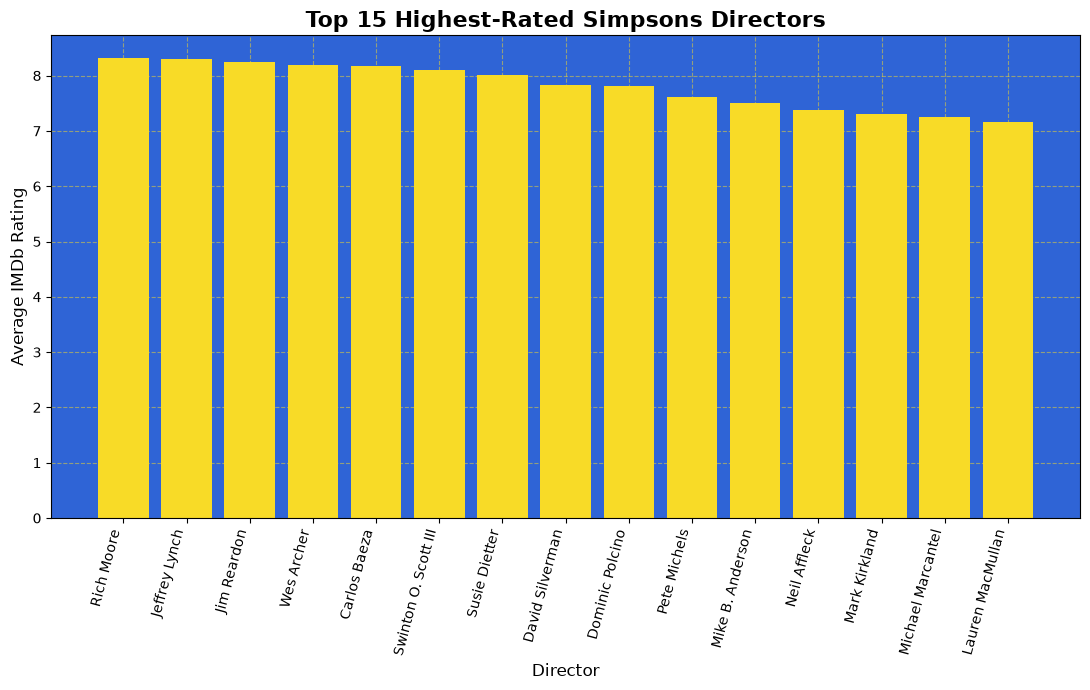

In [67]:
# Plot top 15 highest-rated Simpsons directors
plt.figure(figsize = (11, 7))

plt.bar(
    top_rated_directors.index,
    top_rated_directors['average_rating'],
    color = '#f8db27'
)

plt.title('Top 15 Highest-Rated Simpsons Directors', fontsize = 16, fontweight = 'bold')
plt.xlabel('Director', fontsize = 12)
plt.ylabel('Average IMDb Rating', fontsize = 12)
plt.xticks(rotation = 75, ha = 'right')
plt.grid(linestyle = '--', alpha = 0.5, color = '#f8db27')

ax = plt.gca()
ax.set_facecolor('#2f64d6')

plt.tight_layout()
plt.show()

Rich Moore is the director with the highest average IMDb user rating for his episodes.

## 4.5 Viewership vs Rating & Viewer Engagement

Now, let's calculate how the U.S. viewership, the average IMDb user rating, and the number of IMDb rating votes are related.

In [68]:
# Calculate the linear correlation between the three variables
episodes[
    ['us_viewers_millions', 'average_rating', 'num_votes']
].corr()

,us_viewers_millions,average_rating,num_votes
us_viewers_millions,1.000000,0.703235,0.879839
average_rating,0.703235,1.000000,0.789721
num_votes,0.879839,0.789721,1.000000


All three correlations have values that are strong and positive. We can see these correlations more clearly with regression lines on scatter plots. Let's look at IMDb rating vs U.S. viewership.

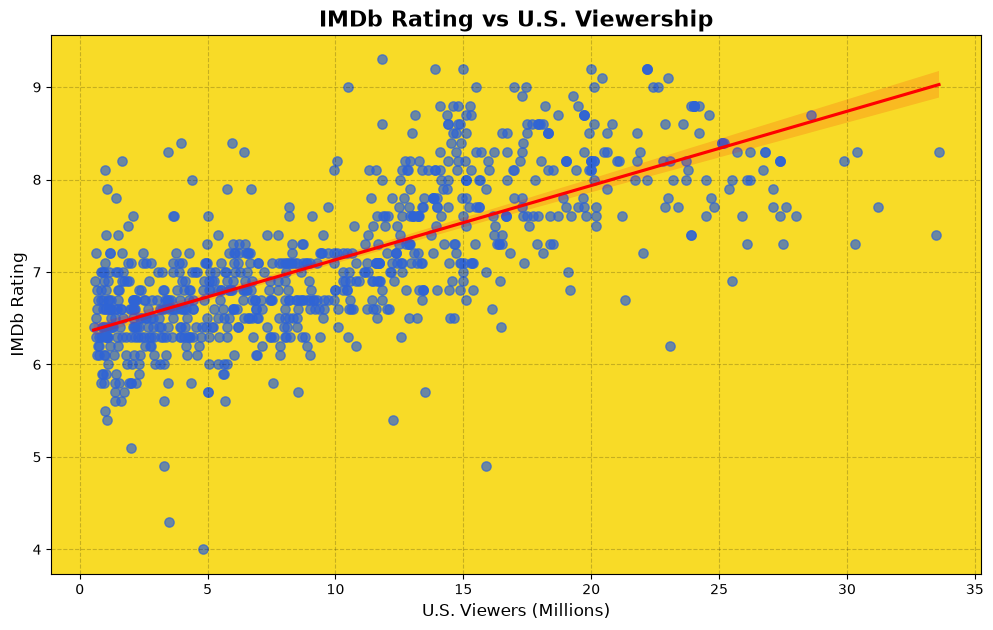

In [69]:
# Plot a regression plot for viewership and IMDb rating
plt.figure(figsize = (12, 7))

ax = sns.regplot(
    data = episodes,
    x = 'us_viewers_millions',
    y = 'average_rating',
    scatter_kws = {'alpha': 0.7,
                  'color' : '#2f64d6',
                  's' : 45},
    line_kws = {'color': 'red'}
)

ax.set_facecolor('#f8db27')

ax.grid(True,
       color = 'black',
       linestyle = '--',
       alpha = 0.2)

plt.title("IMDb Rating vs U.S. Viewership", fontsize = 16,  fontweight = 'bold')
plt.xlabel("U.S. Viewers (Millions)", fontsize = 12)
plt.ylabel("IMDb Rating", fontsize = 12)

plt.show()

IMDb user rating and U.S. viewership have a strong positive correlation, meaning that episodes with higher U.S. viewership tend to have higher IMDb ratings. One possible explanation for this is that particularly popular episodes are more favourably received by audiences. However, it is important to note that this correlation does not establish causation.

Now, let's look at number of IMDb rating votes vs U.S. viewership.

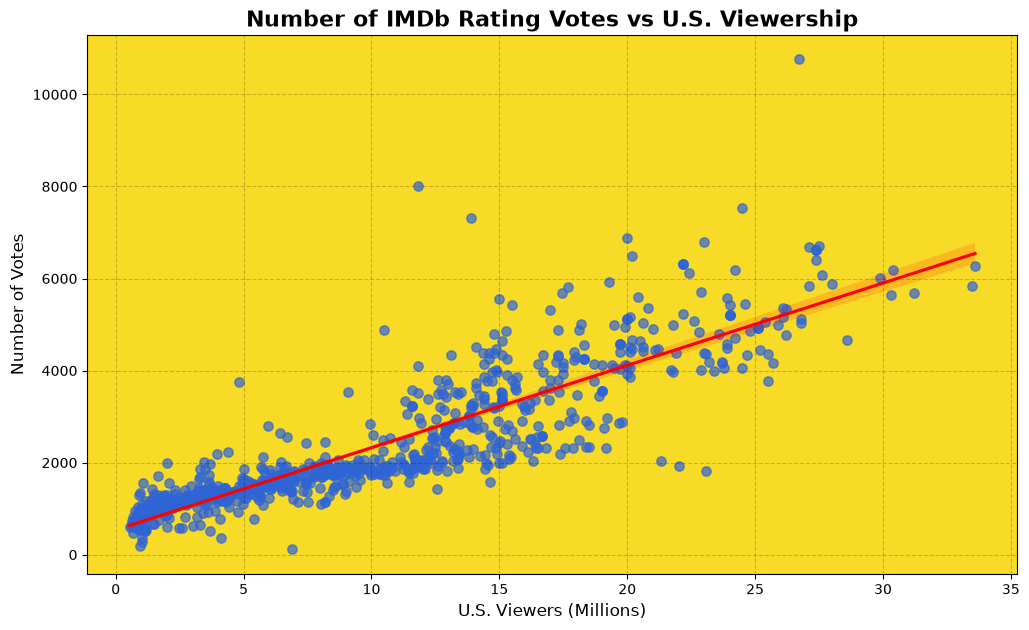

In [70]:
# Plot a regression plot for IMDb rating and viewership
plt.figure(figsize = (12, 7))

ax = sns.regplot(
    data = episodes,
    x = 'us_viewers_millions',
    y = 'num_votes',
    scatter_kws = {'alpha': 0.7,
                  'color' : '#2f64d6',
                  's' : 45},
    line_kws = {'color': 'red'}
)

ax.set_facecolor('#f8db27')

ax.grid(True,
       color = 'black',
       linestyle = '--',
       alpha = 0.2)

plt.title("Number of IMDb Rating Votes vs U.S. Viewership", fontsize = 16,  fontweight = 'bold')
plt.xlabel("U.S. Viewers (Millions)", fontsize = 12)
plt.ylabel("Number of Votes", fontsize = 12)

plt.show()

Number of votes and U.S. viewership have a very strong positive correlation indicating that episodes watched by more people tend to receive more votes on IMDb. This is a fairly intuitive relationship as episodes with more viewers will have more people who can rate them.

Now, let's have a look at IMDb rating vs number of people who rated.

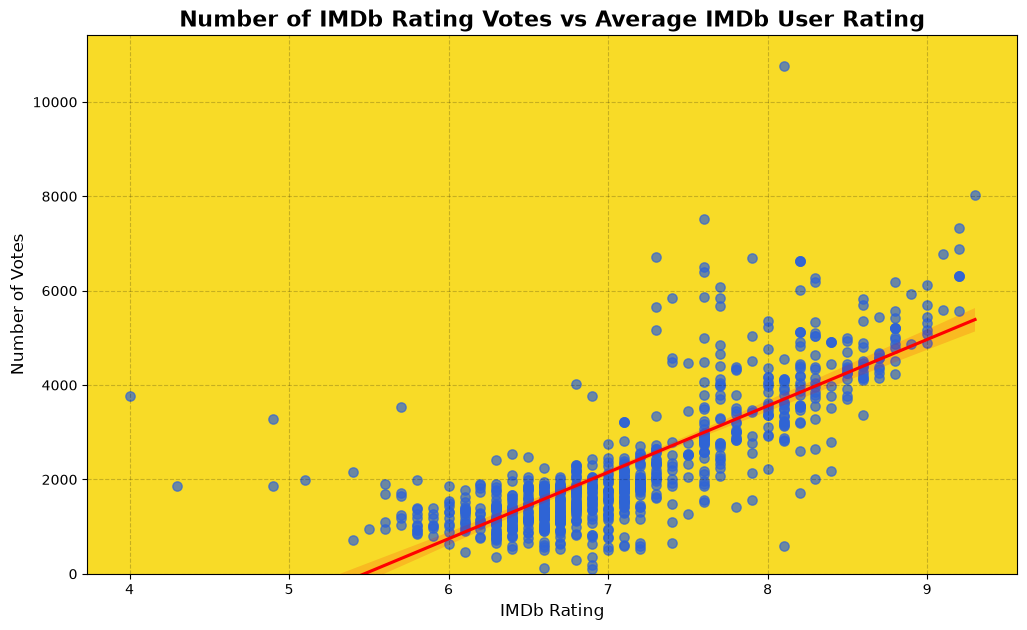

In [71]:
# Plot a regression plot for IMDb rating and number of votes
plt.figure(figsize = (12, 7))

ax = sns.regplot(
    data = episodes,
    x = 'average_rating',
    y = 'num_votes',
    scatter_kws = {'alpha': 0.7,
                  'color' : '#2f64d6',
                  's' : 45},
    line_kws = {'color': 'red'}
)

ax.set_facecolor('#f8db27')

ax.grid(True,
       color = 'black',
       linestyle = '--',
       alpha = 0.2)

ax.set_ylim(bottom = 0)

plt.title("Number of IMDb Rating Votes vs Average IMDb User Rating", fontsize = 16,  fontweight = 'bold')
plt.xlabel("IMDb Rating", fontsize = 12)
plt.ylabel("Number of Votes", fontsize = 12)

plt.show()

IMDb Rating and number of votes have a fairly strong positive correlation meaning that episodes with more IMDb votes tend to have higher ratings. This might suggest that particularly well-known or popular episodes attract more engagement from IMDb users.

# 5. Key Findings

1. The viewership of The Simpsons has consistently declined over its run. There have been peaks in viewership within seasons, but the average viewership has largely decreased with later seasons.
2. The way the IMDb rating of The Simpsons has changed over time is a bit more complicated. The show's average IMDb rating initially increased for its first six seasons, before it began to steadily decline. During the "Golden Age" of seasons 3-8 each season's average IMDb rating never dropped below 8.0, though there are still low-rated episodes in this range, notably season 6's "Another Simpsons Clip Show". The value of this rating mostly decreased, reaching its lowest point at season 30 whereafter a small uptick in rating occurred.
3. John Swartzwelder is the most prolific Simpsons writer by some way, having written 58 episodes over the show's run with an average IMDb rating of 7.9. The writer with the highest average IMDb rating is Greg Daniels, with an average rating of 8.7, though only 8 episodes have been written by him.
4. Steven Dean Moore is the most prolific Simpsons director, having directed 87 episodes in total, followed by Mark Kirkland, who directed 84. The highest-rated director on average was Rich Moore, with an average score of 8.3 for his episodes.
5. IMDb rating, U.S. viewership, and IMDb user engagement were found to be positively correlated with each other, meaning that as one increases, so do the others. Episodes with particularly high IMDb ratings were found to also have high viewership and a high number of votes.

# 6. Conclusion

The project explored the relationship between episode ratings, seasons, writers, and directors throughout the history of The Simpsons. The analysis revealed several interesting patterns.

It is important to recognise that IMDb ratings are based on user-submitted opinions and should not necessarily be considered an objective measure of episode quality.

Additionally, limitations in the availability and consistency of the original data may have influenced some aspects of the analysis.

The viewing figures used in this project are U.S. viewing figures, not global viewership.

When considering the correlations calculated in section 4.5, it is important to remember that correlation does not equate to causation.